In [884]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import math
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.stats import norm
from scipy.stats import f

import seaborn as sns 
from statsmodels.stats.diagnostic import het_breuschpagan, het_white  
from scipy.stats import shapiro 
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_goldfeldquandt

In [885]:
df_2008 = pd.read_csv('/Users/alina/Desktop/Data_2008.csv')
df_2015 = pd.read_csv('/Users/alina/Desktop/Data_2015.csv')
df_Lipetsk_2008 = df_2008[df_2008['region'] == 72]
df_Chelyabinsk_2008 = df_2008[df_2008['region'] == 106]
df_Lipetsk_2015 = df_2015[df_2015['region'] == 72]
df_Chelyabinsk_2015 = df_2015[df_2015['region'] == 106]

/var/folders/p5/6n72_bgn12g00gw692k67yh00000gp/T/ipykernel_42367/4102523110.py:1: DtypeWarning: Columns (375,782,818,907) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2008 = pd.read_csv('/Users/alina/Desktop/Data_2008.csv')


In [886]:
df_Lipetsk_2008['age_squared'] = df_Lipetsk_2008['m_age'] ** 2
df_Chelyabinsk_2008['age_squared'] = df_Chelyabinsk_2008['m_age'] ** 2
df_Lipetsk_2008 = df_Lipetsk_2008[['mj10','mh5','m_age','age_squared', 'mj72.173', 'm_marst', 'mj6', 'm_occup08', 'm_educ', 'mm3', 'mj260', 'mj6.1a']]
df_Chelyabinsk_2008 = df_Chelyabinsk_2008[['mj10','mh5','m_age','age_squared', 'mj72.173', 'm_marst', 'mj6', 'm_occup08', 'm_educ', 'mm3', 'mj260', 'mj6.1a']]

/var/folders/p5/6n72_bgn12g00gw692k67yh00000gp/T/ipykernel_42367/482269908.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_Lipetsk_2008['age_squared'] = df_Lipetsk_2008['m_age'] ** 2
/var/folders/p5/6n72_bgn12g00gw692k67yh00000gp/T/ipykernel_42367/482269908.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_Chelyabinsk_2008['age_squared'] = df_Chelyabinsk_2008['m_age'] ** 2


In [887]:
df_Lipetsk_2015['age_squared'] = df_Lipetsk_2015['t_age'] ** 2
df_Chelyabinsk_2015['age_squared'] = df_Chelyabinsk_2015['t_age'] ** 2
df_Lipetsk_2015 = df_Lipetsk_2015[['tj10','th5','t_age', 'age_squared', 'tj72.173', 't_marst', 'tj6', 't_occup08', 't_educ', 'tm3', 'tj260', 'tj6.1a']]
df_Chelyabinsk_2015 = df_Chelyabinsk_2015[['tj10','th5','t_age', 'age_squared', 'tj72.173', 't_marst', 'tj6', 't_occup08', 't_educ', 'tm3', 'tj260', 'tj6.1a']]

/var/folders/p5/6n72_bgn12g00gw692k67yh00000gp/T/ipykernel_42367/927097019.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_Lipetsk_2015['age_squared'] = df_Lipetsk_2015['t_age'] ** 2
/var/folders/p5/6n72_bgn12g00gw692k67yh00000gp/T/ipykernel_42367/927097019.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_Chelyabinsk_2015['age_squared'] = df_Chelyabinsk_2015['t_age'] ** 2


Переименовываем колонки для 2008 года

In [888]:
df_Lipetsk_2008 = df_Lipetsk_2008.rename(columns={
    'mj10': 'wage',
    'mh5': 'sex',
    'm_age': 'age',
    'age_squared': 'age^2', 
    'mj72.173': 'children',
    'm_marst': 'married',  
    'mj6': 'is_supervisor',
    'm_occup08': 'qualification',
    'm_educ': 'diplom',  
    'mm3': 'health',
    'mj260': 'language',
    'mj6.1a': 'working hours'
})
df_Chelyabinsk_2008 = df_Chelyabinsk_2008.rename(columns={
    'mj10': 'wage',
    'mh5': 'sex',
    'm_age': 'age',
    'age_squared': 'age^2',
    'mj72.173': 'children',
    'm_marst': 'married',  
    'mj6': 'is_supervisor',
    'm_occup08': 'qualification',
    'm_educ': 'diplom',  
    'mm3': 'health',
    'mj260': 'language',
    'mj6.1a': 'working hours'
})



Переименовываем колонки для 2015 года

In [889]:
df_Lipetsk_2015 = df_Lipetsk_2015.rename(columns={
    'tj10': 'wage',
    'th5': 'sex',
    't_age': 'age',
    'age_squared': 'age^2',
    'tj72.173': 'children',
    't_marst': 'married',  
    'tj6': 'is_supervisor',
    't_occup08': 'qualification',
    't_educ': 'diplom',  
    'tm3': 'health',
    'tj260': 'language',
    'tj6.1a': 'working hours'
})

df_Chelyabinsk_2015 = df_Chelyabinsk_2015.rename(columns={
    'tj10': 'wage',
    'th5': 'sex',
    't_age': 'age',
    'age_squared': 'age^2',  
    'tj72.173': 'children',
    't_marst': 'married',  
    'tj6': 'is_supervisor',
    't_occup08': 'qualification',
    't_educ': 'diplom',  
    'tm3': 'health',
    'tj260': 'language',
    'tj6.1a': 'working hours'
})


# 2008 год


Перекодируем значения для Челябинска

In [890]:
df_Chelyabinsk_2008.info()

<class 'pandas.core.frame.DataFrame'>
Index: 167 entries, 2066 to 9493
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wage           88 non-null     float64
 1   sex            167 non-null    float64
 2   age            167 non-null    float64
 3   age^2          167 non-null    float64
 4   children       104 non-null    float64
 5   married        143 non-null    float64
 6   is_supervisor  92 non-null     float64
 7   qualification  92 non-null     float64
 8   diplom         143 non-null    float64
 9   health         167 non-null    float64
 10  language       143 non-null    float64
 11  working hours  92 non-null     float64
dtypes: float64(12)
memory usage: 17.0 KB


In [891]:
# 1 - мужчина, 0 - женщина
df_Chelyabinsk_2008['sex'] = df_Chelyabinsk_2008['sex'].map({1: 1, 2: 0}) 
#1 - состоят в браке, 0 - не состоят
df_Chelyabinsk_2008['married'] = df_Chelyabinsk_2008['married'].map({1: 0, 2: 1, 3:0, 4:0, 5:0, 6:1}) 
#1 - да, 0 - нет
df_Chelyabinsk_2008['is_supervisor'] = df_Chelyabinsk_2008['is_supervisor'].map({1: 1, 2: 0}) 
# чиновники, специалисты высшего уровня и квалифицированные рабочие это в одну группу(1), все остальные в другую
df_Chelyabinsk_2008['qualification'] = df_Chelyabinsk_2008['qualification'].map({0:0, 1:1, 2:1, 3:1, 4:0, 5:0, 6:1, 7:1, 8:1, 9:0}) 
# 1 - да, 0 - нет
df_Chelyabinsk_2008['diplom'] = df_Chelyabinsk_2008['diplom'].map({0: 0, 1: 0, 2:0, 3:0, 4:0, 5:0, 6:0, 7:0, 8:0, 9:0, 10:0, 11:0, 12:0, 13:0,
                                                                   14:0, 15:0, 16:0, 17:0, 18:0, 19:0, 20:0, 21:1, 22:1, 23:1}) 
# 1 - выше среднего, 0 - ниже среднего
df_Chelyabinsk_2008['health'] = df_Chelyabinsk_2008['health'].map({1: 1, 2: 1, 3:1, 4:0, 5:0}) 
# 1 - да, 0 - нет
df_Chelyabinsk_2008['language'] = df_Chelyabinsk_2008['language'].map({1: 1, 2: 0}) 

Перекодирование значений для Липецка

In [892]:
# 1 - мужчина, 0 - женщина
df_Lipetsk_2008['sex'] = df_Lipetsk_2008['sex'].map({1: 1, 2: 0}) 
#1 - состоят в браке, 0 - не состоят
df_Lipetsk_2008['married'] = df_Lipetsk_2008['married'].map({1: 0, 2: 1, 3:0, 4:0, 5:0, 6:1}) 
#1 - да, 0 - нет
df_Lipetsk_2008['is_supervisor'] = df_Lipetsk_2008['is_supervisor'].map({1: 1, 2: 0}) 
# чиновники, специалисты высшего уровня и квалифицированные рабочие это в одну группу(1), все остальные в другую
df_Lipetsk_2008['qualification'] = df_Lipetsk_2008['qualification'].map({0:0, 1:1, 2:1, 3:1, 4:0, 5:0, 6:1, 7:1, 8:1, 9:0}) 
# 1 - да, 0 - нет
df_Lipetsk_2008['diplom'] = df_Lipetsk_2008['diplom'].map({0: 0, 1: 0, 2:0, 3:0, 4:0, 5:0, 6:0, 7:0, 8:0, 9:0, 10:0, 11:0, 12:0, 13:0,
                                                                   14:0, 15:0, 16:0, 17:0, 18:0, 19:0, 20:0, 21:1, 22:1, 23:1}) 
# 1 - выше среднего, 0 - ниже среднего
df_Lipetsk_2008['health'] = df_Lipetsk_2008['health'].map({1: 1, 2: 1, 3:1, 4:0, 5:0}) 
# 1 - да, 0 - нет
df_Lipetsk_2008['language'] = df_Lipetsk_2008['language'].map({1: 1, 2: 0}) 


# 2015 год

In [893]:
# 1 - мужчина, 0 - женщина
df_Lipetsk_2015['sex'] = df_Lipetsk_2015['sex'].map({1: 1, 2: 0}) 
#1 - состоят в браке, 0 - не состоят
df_Lipetsk_2015['married'] = df_Lipetsk_2015['married'].map({1: 0, 2: 1, 3:0, 4:0, 5:0, 6:1}) 
#1 - да, 0 - нет
df_Lipetsk_2015['is_supervisor'] = df_Lipetsk_2015['is_supervisor'].map({1: 1, 2: 0}) 
# 1 - техническая специальность, 0 - гуманитарная
# чиновники, специалисты высшего уровня и квалифицированные рабочие это в одну группу(1), все остальные в другую
df_Lipetsk_2015['qualification'] = df_Lipetsk_2015['qualification'].map({0:0, 1:1, 2:1, 3:1, 4:0, 5:0, 6:1, 7:1, 8:1, 9:0}) 
# 1 - да, 0 - нет
df_Lipetsk_2015['diplom'] = df_Lipetsk_2015['diplom'].map({0: 0, 1: 0, 2:0, 3:0, 4:0, 5:0, 6:0, 7:0, 8:0, 9:0, 10:0, 11:0, 12:0, 13:0,
                                                                   14:0, 15:0, 16:0, 17:0, 18:0, 19:0, 20:0, 21:1, 22:1, 23:1}) 
# 1 - выше среднего, 0 - ниже среднего
df_Lipetsk_2015['health'] = df_Lipetsk_2015['health'].map({1: 1, 2: 1, 3:1, 4:0, 5:0}) 
# 1 - да, 0 - нет
df_Lipetsk_2015['language'] = df_Lipetsk_2015['language'].map({1: 1, 2: 0}) 

In [894]:
# 1 - мужчина, 0 - женщина
df_Chelyabinsk_2015['sex'] = df_Chelyabinsk_2015['sex'].map({1: 1, 2: 0}) 
#1 - состоят в браке, 0 - не состоят
df_Chelyabinsk_2015['married'] = df_Chelyabinsk_2015['married'].map({1: 0, 2: 1, 3:0, 4:0, 5:0, 6:1}) 
#1 - да, 0 - нет
df_Chelyabinsk_2015['is_supervisor'] = df_Chelyabinsk_2015['is_supervisor'].map({1: 1, 2: 0}) 
# чиновники, специалисты высшего уровня и квалифицированные рабочие это в одну группу(1), все остальные в другую
df_Chelyabinsk_2015['qualification'] = df_Chelyabinsk_2015['qualification'].map({0:0, 1:1, 2:1, 3:1, 4:0, 5:0, 6:1, 7:1, 8:1, 9:0}) 
# 1 - да, 0 - нет
df_Chelyabinsk_2015['diplom'] = df_Chelyabinsk_2015['diplom'].map({0: 0, 1: 0, 2:0, 3:0, 4:0, 5:0, 6:0, 7:0, 8:0, 9:0, 10:0, 11:0, 12:0, 13:0,
                                                                   14:0, 15:0, 16:0, 17:0, 18:0, 19:0, 20:0, 21:1, 22:1, 23:1}) 
# 1 - выше среднего, 0 - ниже среднего
df_Chelyabinsk_2015['health'] = df_Chelyabinsk_2015['health'].map({1: 1, 2: 1, 3:1, 4:0, 5:0}) 
# 1 - да, 0 - нет
df_Chelyabinsk_2015['language'] = df_Chelyabinsk_2015['language'].map({1: 1, 2: 0}) 

# Заполнение пропусков

# Челябинск 2008 год

In [895]:
df_Chelyabinsk_2008 = df_Chelyabinsk_2008.dropna(subset=['wage'])
df_Chelyabinsk_2008.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88 entries, 2068 to 9492
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wage           88 non-null     float64
 1   sex            88 non-null     int64  
 2   age            88 non-null     float64
 3   age^2          88 non-null     float64
 4   children       69 non-null     float64
 5   married        88 non-null     float64
 6   is_supervisor  88 non-null     float64
 7   qualification  88 non-null     float64
 8   diplom         88 non-null     float64
 9   health         88 non-null     int64  
 10  language       88 non-null     float64
 11  working hours  88 non-null     float64
dtypes: float64(10), int64(2)
memory usage: 8.9 KB


In [896]:
columns_to_fill = ['children']
df_Chelyabinsk_2008[columns_to_fill] = df_Chelyabinsk_2008[columns_to_fill].fillna(0)


In [897]:
special_values = [99999996,99999997, 99999998, 99999999]

for val in special_values:
    count = (df_Chelyabinsk_2008['wage'] == val).sum()
    сount_2 = (df_Chelyabinsk_2008['working hours'] == val).sum()
    print(f"Значение {val}: {count} строк")
    print(f"Значение {val}: {сount_2} строк")

original_count = len(df_Chelyabinsk_2008)
df_Chelyabinsk_2008 = df_Chelyabinsk_2008[~df_Chelyabinsk_2008['wage'].isin(special_values)]
df_Chelyabinsk_2008 = df_Chelyabinsk_2008[~df_Chelyabinsk_2008['working hours'].isin(special_values)]

Значение 99999996: 0 строк
Значение 99999996: 0 строк
Значение 99999997: 0 строк
Значение 99999997: 0 строк
Значение 99999998: 1 строк
Значение 99999998: 0 строк
Значение 99999999: 0 строк
Значение 99999999: 0 строк


In [898]:
df_Chelyabinsk_2008.describe()

,wage,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours
count,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000
mean,12808.965517,0.402299,40.982759,1843.985632,0.563218,0.517241,0.160920,0.620690,0.252874,0.965517,0.114943,9.505747
std,8855.476171,0.493204,12.896152,1118.135441,0.757922,0.502599,0.369587,0.488028,0.437179,0.183523,0.320802,3.669084
min,1800.000000,0.000000,19.500000,380.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,7000.000000,0.000000,31.500000,992.250000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,8.000000
50%,10000.000000,0.000000,40.000000,1600.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,8.000000
75%,15500.000000,1.000000,50.750000,2575.625000,1.000000,1.000000,0.000000,1.000000,0.500000,1.000000,0.000000,12.000000
max,50000.000000,1.000000,71.500000,5112.250000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000


Переводим зп в рубли 2015 года (индекс ИПЦ = 2,0025)

In [899]:
df_Chelyabinsk_2008['wage'] = df_Chelyabinsk_2008['wage'] * 2.0025

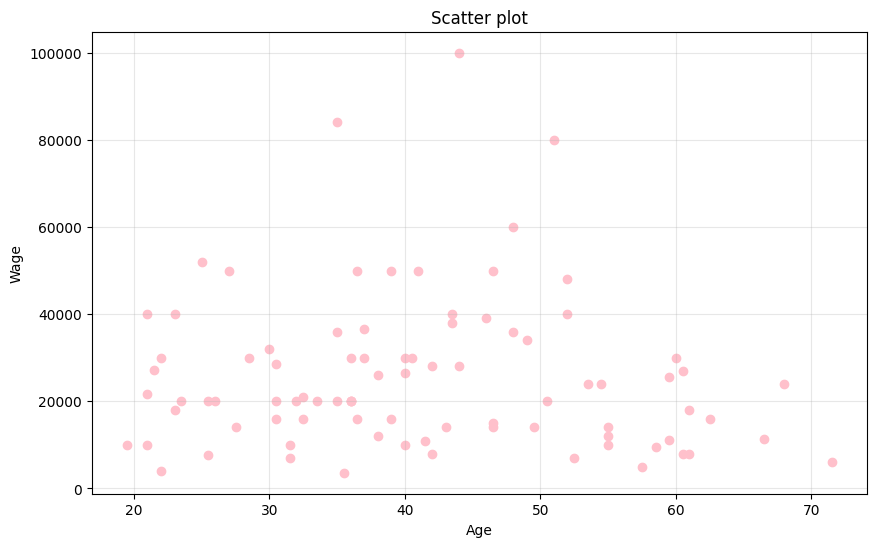

In [900]:
plt.figure(figsize=(10, 6))
plt.scatter(df_Chelyabinsk_2008['age'], df_Chelyabinsk_2008['wage'], color = 'pink')
plt.title('Scatter plot')
plt.xlabel('Age')
plt.ylabel('Wage')
plt.grid(True, alpha=0.3)
plt.show()

Убираем выбросы


Количество выбросов:
По традиционному методу (1.5*IQR): 4 (4.60%)
По 95% доверительному интервалу: 3 (3.45%)


<Figure size 1000x600 with 0 Axes>

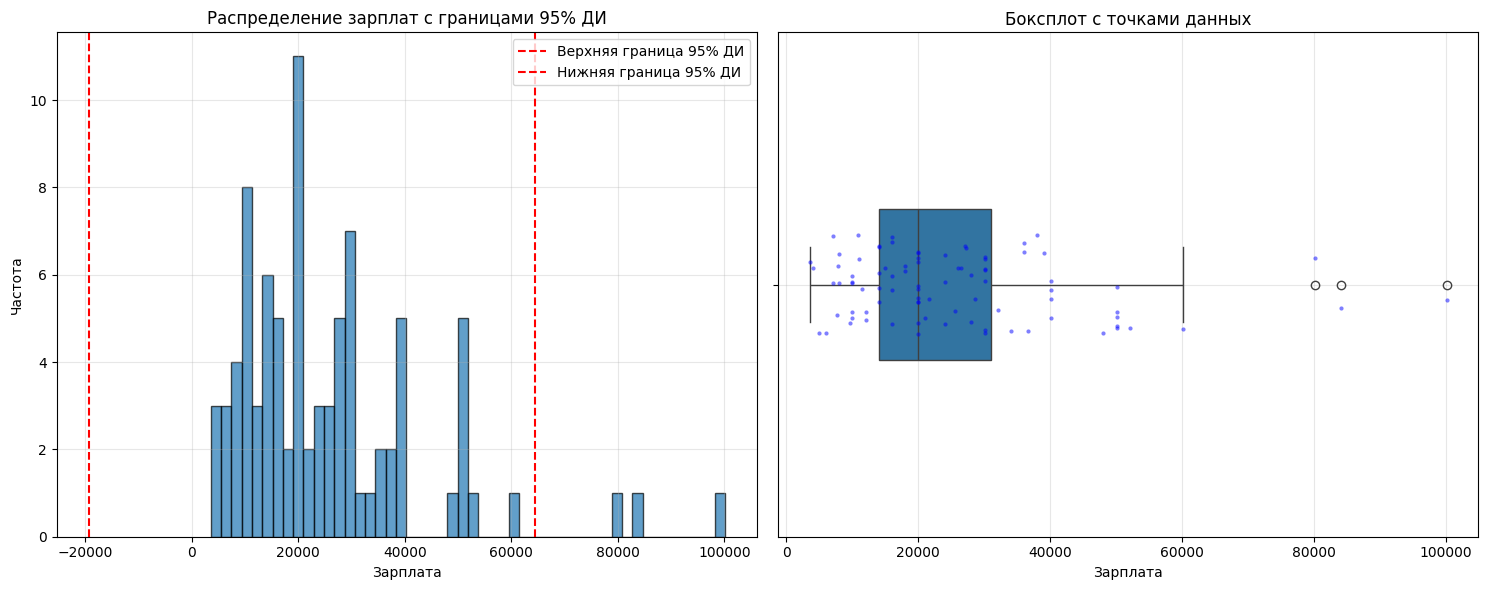

Исходный размер датафрейма: 87
После удаления выбросов: 84
Удалено строк: 3 (3.45%)


In [901]:
plt.figure(figsize=(10, 6))

# 2. Аналитический расчет границ выбросов
def calculate_outlier_bounds(data, confidence_level=0.95):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound_traditional = Q1 - 1.5 * IQR
    upper_bound_traditional = Q3 + 1.5 * IQR

    lower_bound_95 = Q1 - 1.96 * IQR
    upper_bound_95 = Q3 + 1.96 * IQR
    
    z_score = stats.norm.ppf((1 + confidence_level) / 2) 
    mean = data.mean()
    std = data.std()
    lower_bound_stat = mean - z_score * std
    upper_bound_stat = mean + z_score * std
    
    return {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'traditional_bounds': (lower_bound_traditional, upper_bound_traditional),
        '95ci_bounds': (lower_bound_95, upper_bound_95),
        'statistical_bounds': (lower_bound_stat, upper_bound_stat)
    }

# 3. Применяем функцию к данным о зарплате
wage_bounds = calculate_outlier_bounds(df_Chelyabinsk_2008['wage'])

def count_outliers(data, bounds_dict):
    """Подсчет выбросов по разным границам"""
    results = {}
    
    # Традиционные выбросы (1.5*IQR)
    lower_trad, upper_trad = bounds_dict['traditional_bounds']
    trad_outliers = data[(data < lower_trad) | (data > upper_trad)]
    results['traditional'] = {
        'count': len(trad_outliers),
        'percent': len(trad_outliers) / len(data) * 100,
        'values': trad_outliers
    }
    
    # Выбросы для 95% ДИ
    lower_95, upper_95 = bounds_dict['95ci_bounds']
    outliers_95 = data[(data < lower_95) | (data > upper_95)]
    results['95ci'] = {
        'count': len(outliers_95),
        'percent': len(outliers_95) / len(data) * 100,
        'values': outliers_95
    }
    
    return results

outlier_counts = count_outliers(df_Chelyabinsk_2008['wage'], wage_bounds)

print(f"\nКоличество выбросов:")
print(f"По традиционному методу (1.5*IQR): {outlier_counts['traditional']['count']} ({outlier_counts['traditional']['percent']:.2f}%)")
print(f"По 95% доверительному интервалу: {outlier_counts['95ci']['count']} ({outlier_counts['95ci']['percent']:.2f}%)")

#Визуализация распределения с выбросами
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Гистограмма 
axes[0].hist(df_Chelyabinsk_2008['wage'], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=wage_bounds['95ci_bounds'][1], color='red', linestyle='--', label='Верхняя граница 95% ДИ')
axes[0].axvline(x=wage_bounds['95ci_bounds'][0], color='red', linestyle='--', label='Нижняя граница 95% ДИ')
axes[0].set_title('Распределение зарплат с границами 95% ДИ')
axes[0].set_xlabel('Зарплата')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
sns.boxplot(x=df_Chelyabinsk_2008['wage'], ax=axes[1], whis=1.96, width=0.3)
sns.stripplot(x=df_Chelyabinsk_2008['wage'], ax=axes[1], color='blue', alpha=0.5, jitter=True, size=3)
axes[1].set_title('Боксплот с точками данных')
axes[1].set_xlabel('Зарплата')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#Код для удаления выбросов по 95% ДИ
def remove_outliers_by_bounds(df, column_name, lower_bound, upper_bound):
    """
    Удаляет строки, где значение в указанном столбце выходит за границы
    """
    original_len = len(df)
    filtered_df = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)].copy()
    removed_count = original_len - len(filtered_df)
    
    print(f"Исходный размер датафрейма: {original_len}")
    print(f"После удаления выбросов: {len(filtered_df)}")
    print(f"Удалено строк: {removed_count} ({removed_count/original_len*100:.2f}%)")
    
    return filtered_df

# Удаляем выбросы по 95% ДИ (или можно использовать традиционные границы)
df_Chelyabinsk_2008_clean = remove_outliers_by_bounds(
    df_Chelyabinsk_2008, 
    'wage', 
    wage_bounds['95ci_bounds'][0], 
    wage_bounds['95ci_bounds'][1]
)

In [902]:
df_Chelyabinsk_2008 = df_Chelyabinsk_2008_clean
df_Chelyabinsk_2008.shape

(84, 12)

# Липецк 2008 год

In [903]:
df_Lipetsk_2008 = df_Lipetsk_2008.dropna(subset=['wage'])
df_Lipetsk_2008.info()

<class 'pandas.core.frame.DataFrame'>
Index: 166 entries, 1286 to 9308
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wage           166 non-null    float64
 1   sex            166 non-null    int64  
 2   age            166 non-null    float64
 3   age^2          166 non-null    float64
 4   children       116 non-null    float64
 5   married        166 non-null    float64
 6   is_supervisor  166 non-null    float64
 7   qualification  166 non-null    float64
 8   diplom         166 non-null    float64
 9   health         166 non-null    int64  
 10  language       166 non-null    float64
 11  working hours  166 non-null    float64
dtypes: float64(10), int64(2)
memory usage: 16.9 KB


In [904]:
df_Lipetsk_2008 = df_Lipetsk_2008.dropna(subset=['wage'])
columns_to_fill = ['children']
df_Lipetsk_2008[columns_to_fill] = df_Lipetsk_2008[columns_to_fill].fillna(0)


In [905]:
special_values = [99999996,99999997, 99999998, 99999999]

for val in special_values:
    count = (df_Lipetsk_2008['wage'] == val).sum()
    сount_2 = (df_Lipetsk_2008['working hours'] == val).sum()
    print(f"Значение {val}: {count} строк")
    print(f"Значение {val}: {сount_2} строк")

original_count = len(df_Lipetsk_2008)
df_Lipetsk_2008 = df_Lipetsk_2008[~df_Lipetsk_2008['wage'].isin(special_values)]
df_Lipetsk_2008 = df_Lipetsk_2008[~df_Lipetsk_2008['working hours'].isin(special_values)]


Значение 99999996: 0 строк
Значение 99999996: 0 строк
Значение 99999997: 0 строк
Значение 99999997: 0 строк
Значение 99999998: 6 строк
Значение 99999998: 0 строк
Значение 99999999: 0 строк
Значение 99999999: 0 строк


In [906]:
df_Lipetsk_2008.describe() #странное значение минимума в зп!!! возможно, ошибка в единице измерения

,wage,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,10746.250000,0.456250,42.775000,2068.046875,0.268750,0.550000,0.125000,0.593750,0.300000,0.925000,0.462500,8.600000
std,10594.331506,0.499646,15.486939,1351.980042,0.522715,0.499056,0.331757,0.492674,0.459696,0.264218,0.500157,3.213963
min,1500.000000,0.000000,17.500000,306.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,5500.000000,0.000000,27.875000,777.062500,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,8.000000
50%,8000.000000,0.000000,44.750000,2002.625000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,8.000000
75%,14075.000000,1.000000,54.500000,2970.250000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,10.000000
max,120000.000000,1.000000,77.000000,5929.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000


Переводим зп в рубли 2015 года (индекс ИПЦ = 2,0278)

In [907]:
df_Lipetsk_2008['wage'] = df_Lipetsk_2008['wage'] * 2.0278

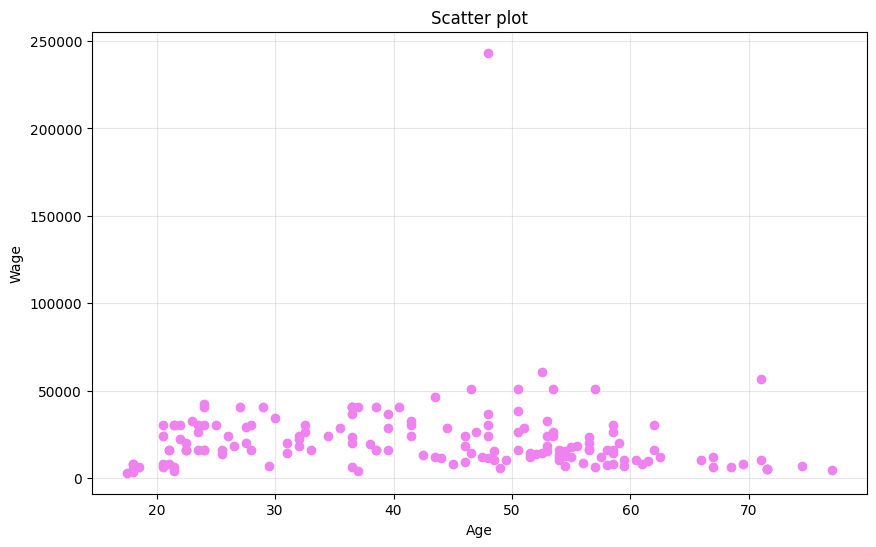

In [908]:
plt.figure(figsize=(10, 6))
plt.scatter(df_Lipetsk_2008['age'], df_Lipetsk_2008['wage'], color = 'violet')
plt.title('Scatter plot')
plt.xlabel('Age')
plt.ylabel('Wage')
plt.grid(True, alpha=0.3)
plt.show()

Убираем выбросы


Количество выбросов:
По традиционному методу (1.5*IQR): 3 (1.88%)
По 95% доверительному интервалу: 1 (0.62%)


<Figure size 1000x600 with 0 Axes>

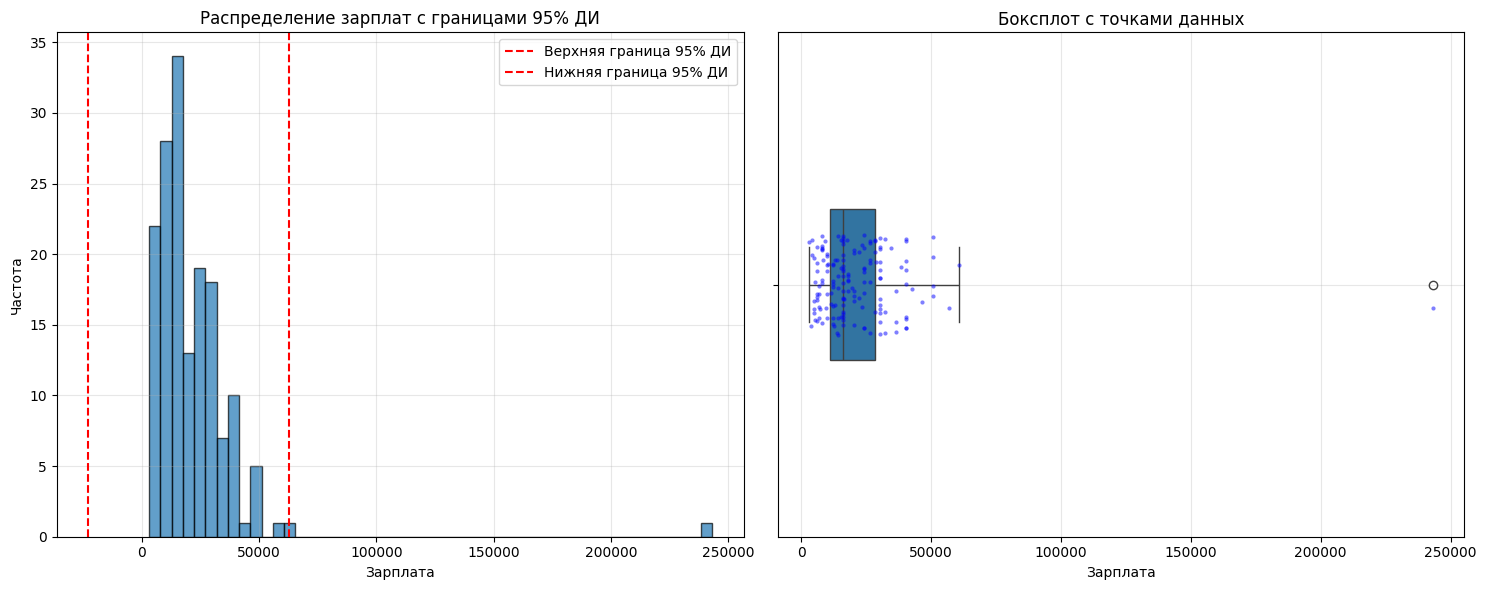

Исходный размер датафрейма: 160
После удаления выбросов: 159
Удалено строк: 1 (0.62%)


In [909]:
plt.figure(figsize=(10, 6))

# 2. Аналитический расчет границ выбросов
def calculate_outlier_bounds(data, confidence_level=0.95):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound_traditional = Q1 - 1.5 * IQR
    upper_bound_traditional = Q3 + 1.5 * IQR

    lower_bound_95 = Q1 - 1.96 * IQR
    upper_bound_95 = Q3 + 1.96 * IQR
    
    z_score = stats.norm.ppf((1 + confidence_level) / 2) 
    mean = data.mean()
    std = data.std()
    lower_bound_stat = mean - z_score * std
    upper_bound_stat = mean + z_score * std
    
    return {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'traditional_bounds': (lower_bound_traditional, upper_bound_traditional),
        '95ci_bounds': (lower_bound_95, upper_bound_95),
        'statistical_bounds': (lower_bound_stat, upper_bound_stat)
    }

# 3. Применяем функцию к данным о зарплате
def count_outliers(data, bounds_dict):
    """Подсчет выбросов по разным границам"""
    results = {}
    
    # Традиционные выбросы (1.5*IQR)
    lower_trad, upper_trad = bounds_dict['traditional_bounds']
    trad_outliers = data[(data < lower_trad) | (data > upper_trad)]
    results['traditional'] = {
        'count': len(trad_outliers),
        'percent': len(trad_outliers) / len(data) * 100,
        'values': trad_outliers
    }
    
    # Выбросы для 95% ДИ
    lower_95, upper_95 = bounds_dict['95ci_bounds']
    outliers_95 = data[(data < lower_95) | (data > upper_95)]
    results['95ci'] = {
        'count': len(outliers_95),
        'percent': len(outliers_95) / len(data) * 100,
        'values': outliers_95
    }
    
    return results

wage_bounds = calculate_outlier_bounds(df_Lipetsk_2008['wage'])

outlier_counts = count_outliers(df_Lipetsk_2008['wage'], wage_bounds)

print(f"\nКоличество выбросов:")
print(f"По традиционному методу (1.5*IQR): {outlier_counts['traditional']['count']} ({outlier_counts['traditional']['percent']:.2f}%)")
print(f"По 95% доверительному интервалу: {outlier_counts['95ci']['count']} ({outlier_counts['95ci']['percent']:.2f}%)")

#Визуализация распределения с выбросами
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Гистограмма 
axes[0].hist(df_Lipetsk_2008['wage'], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=wage_bounds['95ci_bounds'][1], color='red', linestyle='--', label='Верхняя граница 95% ДИ')
axes[0].axvline(x=wage_bounds['95ci_bounds'][0], color='red', linestyle='--', label='Нижняя граница 95% ДИ')
axes[0].set_title('Распределение зарплат с границами 95% ДИ')
axes[0].set_xlabel('Зарплата')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
sns.boxplot(x=df_Lipetsk_2008['wage'], ax=axes[1], whis=1.96, width=0.3)
sns.stripplot(x=df_Lipetsk_2008['wage'], ax=axes[1], color='blue', alpha=0.5, jitter=True, size=3)
axes[1].set_title('Боксплот с точками данных')
axes[1].set_xlabel('Зарплата')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#Код для удаления выбросов по 95% ДИ
def remove_outliers_by_bounds(df, column_name, lower_bound, upper_bound):
    """
    Удаляет строки, где значение в указанном столбце выходит за границы
    """
    original_len = len(df)
    filtered_df = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)].copy()
    removed_count = original_len - len(filtered_df)
    
    print(f"Исходный размер датафрейма: {original_len}")
    print(f"После удаления выбросов: {len(filtered_df)}")
    print(f"Удалено строк: {removed_count} ({removed_count/original_len*100:.2f}%)")
    
    return filtered_df

# Удаляем выбросы по 95% ДИ (или можно использовать традиционные границы)
df_Lipetsk_2008_clean = remove_outliers_by_bounds(
    df_Lipetsk_2008, 
    'wage', 
    wage_bounds['95ci_bounds'][0], 
    wage_bounds['95ci_bounds'][1]
)

In [910]:
df_Lipetsk_2008 = df_Lipetsk_2008_clean
df_Lipetsk_2008.shape

(159, 12)

# Челябинск 2015 год

In [911]:
df_Chelyabinsk_2015 = df_Chelyabinsk_2015.dropna(subset=['wage'])
df_Chelyabinsk_2015.info()

<class 'pandas.core.frame.DataFrame'>
Index: 130 entries, 1321 to 12352
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wage           130 non-null    float64
 1   sex            130 non-null    int64  
 2   age            130 non-null    float64
 3   age^2          130 non-null    float64
 4   children       99 non-null     float64
 5   married        130 non-null    float64
 6   is_supervisor  130 non-null    float64
 7   qualification  130 non-null    float64
 8   diplom         130 non-null    float64
 9   health         130 non-null    int64  
 10  language       130 non-null    float64
 11  working hours  130 non-null    float64
dtypes: float64(10), int64(2)
memory usage: 13.2 KB


In [912]:
columns_to_fill = ['children']
df_Chelyabinsk_2015[columns_to_fill] = df_Chelyabinsk_2015[columns_to_fill].fillna(0)


In [913]:
special_values = [99999996,99999997, 99999998, 99999999]

for val in special_values:
    count = (df_Chelyabinsk_2015['wage'] == val).sum()
    сount_2 = (df_Chelyabinsk_2015['working hours'] == val).sum()
    print(f"Значение {val}: {count} строк")
    print(f"Значение {val}: {сount_2} строк")

original_count = len(df_Chelyabinsk_2015)
df_Chelyabinsk_2015 = df_Chelyabinsk_2015[~df_Chelyabinsk_2015['wage'].isin(special_values)]
df_Chelyabinsk_2015 = df_Chelyabinsk_2015[~df_Chelyabinsk_2015['working hours'].isin(special_values)]




Значение 99999996: 0 строк
Значение 99999996: 6 строк
Значение 99999997: 0 строк
Значение 99999997: 1 строк
Значение 99999998: 1 строк
Значение 99999998: 0 строк
Значение 99999999: 0 строк
Значение 99999999: 0 строк


In [914]:
df_Chelyabinsk_2015.describe()


,wage,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours
count,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000,122.000000
mean,24831.885246,0.409836,42.270492,1940.262295,0.524590,0.516393,0.295082,0.655738,0.409836,0.975410,0.311475,9.909836
std,13710.369505,0.493831,12.439298,1145.655944,0.694882,0.501792,0.457960,0.477086,0.493831,0.155511,0.465006,4.203509
min,2000.000000,0.000000,19.000000,361.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,16000.000000,0.000000,33.000000,1089.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,8.000000
50%,22000.000000,0.000000,40.500000,1640.250000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,8.000000
75%,30000.000000,1.000000,50.000000,2500.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,12.000000
max,84000.000000,1.000000,78.500000,6162.250000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000


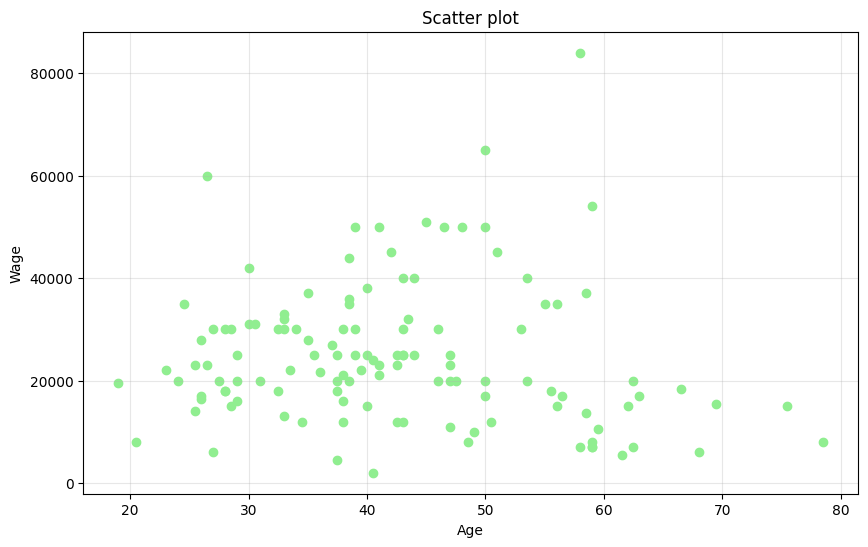

In [915]:
plt.figure(figsize=(10, 6))
plt.scatter(df_Chelyabinsk_2015['age'], df_Chelyabinsk_2015['wage'], color = 'lightgreen')
plt.title('Scatter plot')
plt.xlabel('Age')
plt.ylabel('Wage')
plt.grid(True, alpha=0.3)
plt.show()

Удаляем выбросы


Количество выбросов:
По традиционному методу (1.5*IQR): 4 (3.28%)
По 95% доверительному интервалу: 3 (2.46%)


<Figure size 1000x600 with 0 Axes>

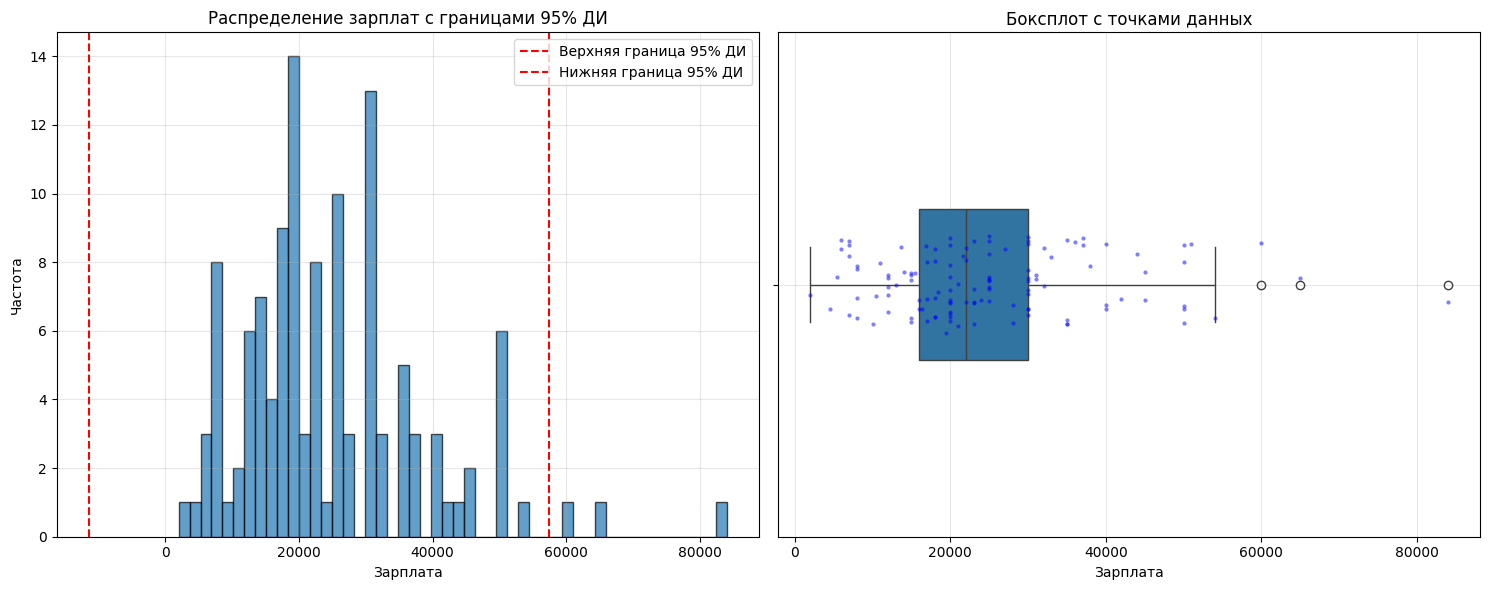

Исходный размер датафрейма: 122
После удаления выбросов: 119
Удалено строк: 3 (2.46%)


In [916]:
plt.figure(figsize=(10, 6))

# 2. Аналитический расчет границ выбросов
def calculate_outlier_bounds(data, confidence_level=0.95):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound_traditional = Q1 - 1.5 * IQR
    upper_bound_traditional = Q3 + 1.5 * IQR

    lower_bound_95 = Q1 - 1.96 * IQR
    upper_bound_95 = Q3 + 1.96 * IQR
    
    z_score = stats.norm.ppf((1 + confidence_level) / 2) 
    mean = data.mean()
    std = data.std()
    lower_bound_stat = mean - z_score * std
    upper_bound_stat = mean + z_score * std
    
    return {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'traditional_bounds': (lower_bound_traditional, upper_bound_traditional),
        '95ci_bounds': (lower_bound_95, upper_bound_95),
        'statistical_bounds': (lower_bound_stat, upper_bound_stat)
    }

# 3. Применяем функцию к данным о зарплате
wage_bounds = calculate_outlier_bounds(df_Chelyabinsk_2015['wage'])

outlier_counts = count_outliers(df_Chelyabinsk_2015['wage'], wage_bounds)

print(f"\nКоличество выбросов:")
print(f"По традиционному методу (1.5*IQR): {outlier_counts['traditional']['count']} ({outlier_counts['traditional']['percent']:.2f}%)")
print(f"По 95% доверительному интервалу: {outlier_counts['95ci']['count']} ({outlier_counts['95ci']['percent']:.2f}%)")

#Визуализация распределения с выбросами
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Гистограмма 
axes[0].hist(df_Chelyabinsk_2015['wage'], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=wage_bounds['95ci_bounds'][1], color='red', linestyle='--', label='Верхняя граница 95% ДИ')
axes[0].axvline(x=wage_bounds['95ci_bounds'][0], color='red', linestyle='--', label='Нижняя граница 95% ДИ')
axes[0].set_title('Распределение зарплат с границами 95% ДИ')
axes[0].set_xlabel('Зарплата')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
sns.boxplot(x=df_Chelyabinsk_2015['wage'], ax=axes[1], whis=1.96, width=0.3)
sns.stripplot(x=df_Chelyabinsk_2015['wage'], ax=axes[1], color='blue', alpha=0.5, jitter=True, size=3)
axes[1].set_title('Боксплот с точками данных')
axes[1].set_xlabel('Зарплата')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#Код для удаления выбросов по 95% ДИ
def remove_outliers_by_bounds(df, column_name, lower_bound, upper_bound):
    """
    Удаляет строки, где значение в указанном столбце выходит за границы
    """
    original_len = len(df)
    filtered_df = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)].copy()
    removed_count = original_len - len(filtered_df)
    
    print(f"Исходный размер датафрейма: {original_len}")
    print(f"После удаления выбросов: {len(filtered_df)}")
    print(f"Удалено строк: {removed_count} ({removed_count/original_len*100:.2f}%)")
    
    return filtered_df

# Удаляем выбросы по 95% ДИ (или можно использовать традиционные границы)
df_Chelyabinsk_2015_clean = remove_outliers_by_bounds(
    df_Chelyabinsk_2015, 
    'wage', 
    wage_bounds['95ci_bounds'][0], 
    wage_bounds['95ci_bounds'][1]
)

In [917]:
df_Chelyabinsk_2015 = df_Chelyabinsk_2015_clean
df_Chelyabinsk_2015.shape

(119, 12)

# Липецк 2015 год

In [918]:
df_Lipetsk_2015 = df_Lipetsk_2015.dropna(subset=['wage'])
df_Lipetsk_2015.info()

<class 'pandas.core.frame.DataFrame'>
Index: 168 entries, 800 to 12069
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wage           168 non-null    float64
 1   sex            168 non-null    int64  
 2   age            168 non-null    float64
 3   age^2          168 non-null    float64
 4   children       115 non-null    float64
 5   married        168 non-null    float64
 6   is_supervisor  168 non-null    float64
 7   qualification  168 non-null    float64
 8   diplom         168 non-null    float64
 9   health         167 non-null    float64
 10  language       168 non-null    float64
 11  working hours  168 non-null    float64
dtypes: float64(11), int64(1)
memory usage: 17.1 KB


In [919]:

columns_to_fill = ['children', 'health']
df_Lipetsk_2015[columns_to_fill] = df_Lipetsk_2015[columns_to_fill].fillna(0)



In [920]:
special_values = [99999996,99999997, 99999998, 99999999]

for val in special_values:
    count = (df_Lipetsk_2015['wage'] == val).sum()
    сount_2 = (df_Lipetsk_2015['working hours'] == val).sum()
    print(f"Значение {val}: {count} строк")
    print(f"Значение {val}: {сount_2} строк")

original_count = len(df_Lipetsk_2015)
df_Lipetsk_2015 = df_Lipetsk_2015[~df_Lipetsk_2015['wage'].isin(special_values)]
df_Lipetsk_2015 = df_Lipetsk_2015[~df_Lipetsk_2015['working hours'].isin(special_values)]

Значение 99999996: 0 строк
Значение 99999996: 0 строк
Значение 99999997: 0 строк
Значение 99999997: 0 строк
Значение 99999998: 7 строк
Значение 99999998: 0 строк
Значение 99999999: 0 строк
Значение 99999999: 0 строк


In [921]:
df_Lipetsk_2015.describe()

,wage,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,18263.354037,0.490683,39.677019,1723.742236,0.527950,0.596273,0.173913,0.695652,0.428571,0.937888,0.142857,8.695652
std,9398.887497,0.501473,12.264202,1063.271526,0.750517,0.492175,0.380217,0.461566,0.496416,0.242112,0.351019,2.801882
min,3000.000000,0.000000,20.500000,420.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
25%,12000.000000,0.000000,29.000000,841.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,8.000000
50%,16000.000000,0.000000,39.000000,1521.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,8.000000
75%,23000.000000,1.000000,48.000000,2304.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,8.000000
max,50000.000000,1.000000,70.500000,4970.250000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000


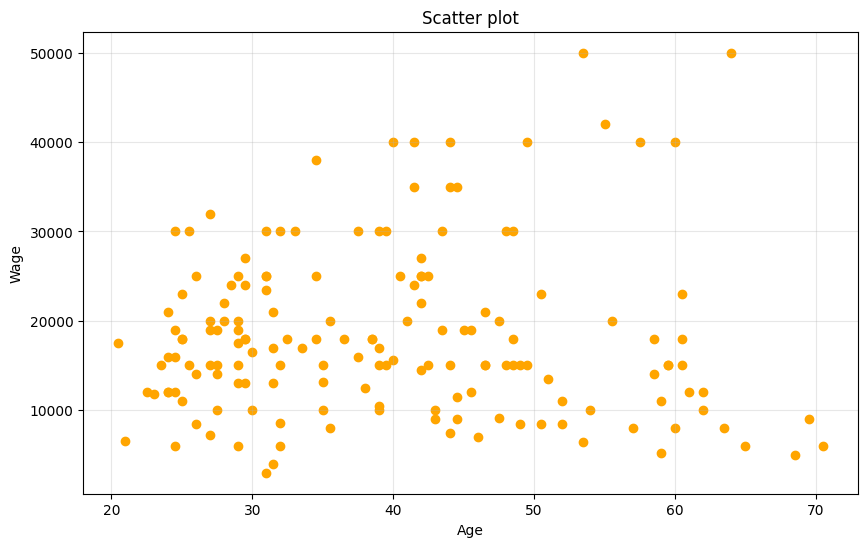

In [922]:
plt.figure(figsize=(10, 6))
plt.scatter(df_Lipetsk_2015['age'], df_Lipetsk_2015['wage'], color = 'orange')
plt.title('Scatter plot')
plt.xlabel('Age')
plt.ylabel('Wage')
plt.grid(True, alpha=0.3)
plt.show()

Удаляем выбросы


Количество выбросов:
По традиционному методу (1.5*IQR): 9 (5.59%)
По 95% доверительному интервалу: 2 (1.24%)


<Figure size 1000x600 with 0 Axes>

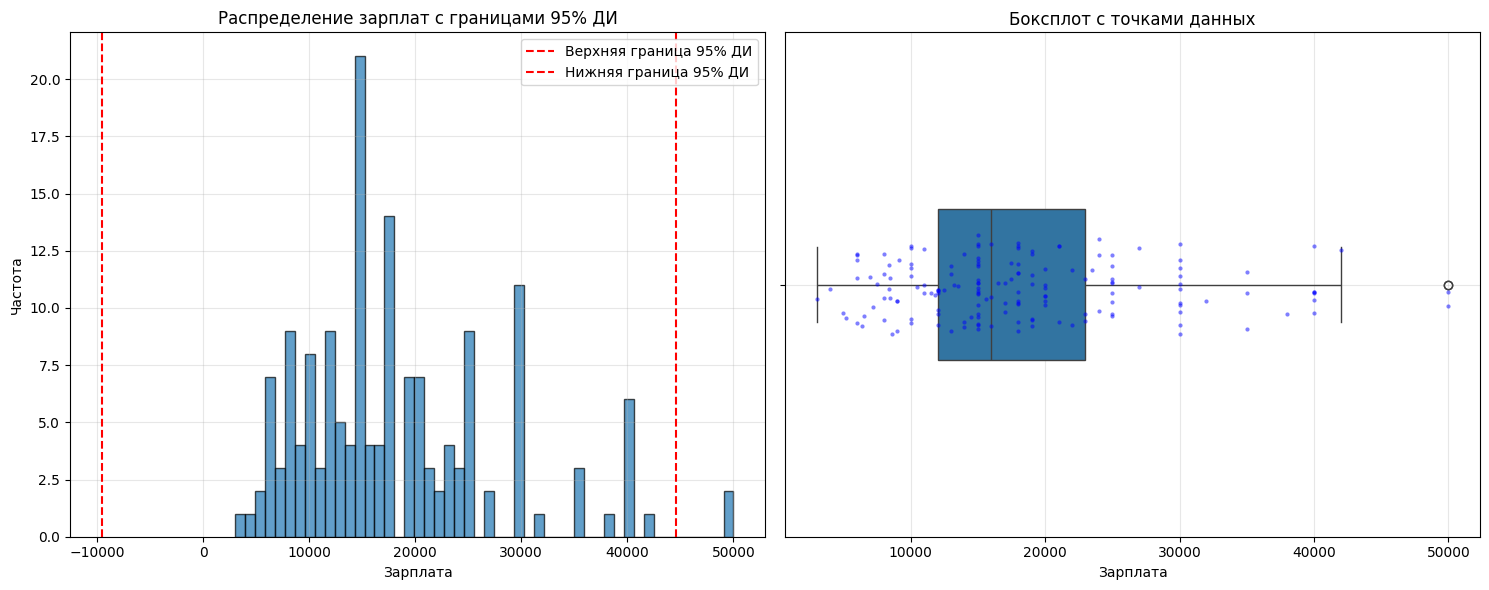

Исходный размер датафрейма: 161
После удаления выбросов: 159
Удалено строк: 2 (1.24%)


In [923]:
plt.figure(figsize=(10, 6))

# 2. Аналитический расчет границ выбросов
def calculate_outlier_bounds(data, confidence_level=0.95):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound_traditional = Q1 - 1.5 * IQR
    upper_bound_traditional = Q3 + 1.5 * IQR

    lower_bound_95 = Q1 - 1.96 * IQR
    upper_bound_95 = Q3 + 1.96 * IQR
    
    z_score = stats.norm.ppf((1 + confidence_level) / 2) 
    mean = data.mean()
    std = data.std()
    lower_bound_stat = mean - z_score * std
    upper_bound_stat = mean + z_score * std
    
    return {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'traditional_bounds': (lower_bound_traditional, upper_bound_traditional),
        '95ci_bounds': (lower_bound_95, upper_bound_95),
        'statistical_bounds': (lower_bound_stat, upper_bound_stat)
    }

# 3. Применяем функцию к данным о зарплате
wage_bounds = calculate_outlier_bounds(df_Lipetsk_2015['wage'])

outlier_counts = count_outliers(df_Lipetsk_2015['wage'], wage_bounds)

print(f"\nКоличество выбросов:")
print(f"По традиционному методу (1.5*IQR): {outlier_counts['traditional']['count']} ({outlier_counts['traditional']['percent']:.2f}%)")
print(f"По 95% доверительному интервалу: {outlier_counts['95ci']['count']} ({outlier_counts['95ci']['percent']:.2f}%)")

#Визуализация распределения с выбросами
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Гистограмма 
axes[0].hist(df_Lipetsk_2015['wage'], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=wage_bounds['95ci_bounds'][1], color='red', linestyle='--', label='Верхняя граница 95% ДИ')
axes[0].axvline(x=wage_bounds['95ci_bounds'][0], color='red', linestyle='--', label='Нижняя граница 95% ДИ')
axes[0].set_title('Распределение зарплат с границами 95% ДИ')
axes[0].set_xlabel('Зарплата')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
sns.boxplot(x=df_Lipetsk_2015['wage'], ax=axes[1], whis=1.96, width=0.3)
sns.stripplot(x=df_Lipetsk_2015['wage'], ax=axes[1], color='blue', alpha=0.5, jitter=True, size=3)
axes[1].set_title('Боксплот с точками данных')
axes[1].set_xlabel('Зарплата')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#Код для удаления выбросов по 95% ДИ
def remove_outliers_by_bounds(df, column_name, lower_bound, upper_bound):
    """
    Удаляет строки, где значение в указанном столбце выходит за границы
    """
    original_len = len(df)
    filtered_df = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)].copy()
    removed_count = original_len - len(filtered_df)
    
    print(f"Исходный размер датафрейма: {original_len}")
    print(f"После удаления выбросов: {len(filtered_df)}")
    print(f"Удалено строк: {removed_count} ({removed_count/original_len*100:.2f}%)")
    
    return filtered_df

# Удаляем выбросы по 95% ДИ (или можно использовать традиционные границы)
df_Lipetsk_2015_clean = remove_outliers_by_bounds(
    df_Lipetsk_2015, 
    'wage', 
    wage_bounds['95ci_bounds'][0], 
    wage_bounds['95ci_bounds'][1]
)

In [924]:
df_Lipetsk_2015 = df_Lipetsk_2015_clean
df_Lipetsk_2015.shape

(159, 12)

# МНК оценка

# Липецк 2008

In [925]:
df_Lipetsk_2008['lnWage'] = np.log(df_Lipetsk_2008['wage'])
df_Lipetsk_2008 = df_Lipetsk_2008.drop(columns = ['wage'], axis = 1)
df_Lipetsk_2008.head()

,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours,lnWage
1286,0,52.5,2756.25,1.0,0.0,1.0,1.0,1.0,1,0.0,7.0,9.560617
1287,0,57.0,3249.00,0.0,0.0,0.0,0.0,0.0,1,0.0,8.0,8.713319
1288,0,51.5,2652.25,0.0,1.0,1.0,1.0,0.0,1,0.0,8.0,9.560617
1289,1,55.0,3025.00,0.0,1.0,0.0,0.0,0.0,1,0.0,24.0,9.406466
1290,0,67.0,4489.00,0.0,0.0,0.0,0.0,0.0,0,0.0,12.0,8.713319


In [927]:
#Центрирование возраста, чтобы убрать совершенную мультиколлинеарность

#df_Lipetsk_2008['age'] = df_Lipetsk_2008['age'] - df_Lipetsk_2008['age'].mean()
#df_Lipetsk_2008['age^2'] = df_Lipetsk_2008['age'] ** 2
X = df_Lipetsk_2008[['sex', 'age', 'age^2',  'children', 'married', 'is_supervisor', 'qualification', 'diplom', 'health', 'language', 'working hours']]
y = df_Lipetsk_2008['lnWage']
X = sm.add_constant(X)  
model = sm.OLS(y, X)   
results = model.fit()  
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                 lnWage   R-squared:                       0.543
Model:                            OLS   Adj. R-squared:                  0.509
Method:                 Least Squares   F-statistic:                     15.90
Date:                Mon, 22 Dec 2025   Prob (F-statistic):           3.66e-20
Time:                        11:31:30   Log-Likelihood:                -95.394
No. Observations:                 159   AIC:                             214.8
Df Residuals:                     147   BIC:                             251.6
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             7.8898      0.335     23.548

In [928]:
vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif

,Variable,VIF
0,const,84.901050
1,sex,1.150539
2,age,48.095256
3,age^2,47.331216
4,children,1.308431
5,married,1.310739
6,is_supervisor,1.298844
7,qualification,1.392653
8,diplom,1.221302
9,health,1.181416


In [929]:
# Тест Бройша-Пагана
bp_test = het_breuschpagan(results.resid, results.model.exog)
labels_bp = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print("Breusch-Pagan test:", dict(zip(labels_bp, bp_test)))

Breusch-Pagan test: {'LM Statistic': np.float64(18.786243246821282), 'LM-Test p-value': np.float64(0.06504009795131434), 'F-Statistic': np.float64(1.7904985159999105), 'F-Test p-value': np.float64(0.060396207424952955)}


In [930]:
# Тест Уайта
white_test = het_white(results.resid, results.model.exog)
labels_white = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Statistic p-value']
print("White test:", dict(zip(labels_white, white_test)))

White test: {'Test Statistic': np.float64(84.71561111556831), 'Test Statistic p-value': np.float64(0.08280696887278127), 'F-Statistic': np.float64(1.509383123841976), 'F-Statistic p-value': np.float64(0.0338045353661627)}


In [931]:
# Goldfeld-Quandt
gq_test = het_goldfeldquandt(results.resid, results.model.exog)
labels_gq = ['F-Statistic', 'p-value', 'Alternative']
print("Goldfeld-Quandt test:", dict(zip(labels_gq, gq_test)))

Goldfeld-Quandt test: {'F-Statistic': np.float64(0.750968524661775), 'p-value': np.float64(0.8788168150494418), 'Alternative': 'increasing'}


In [932]:
# Jarque-Bera
jb_test = jarque_bera(results.resid)
labels_jb = ['JB Statistic', 'p-value', 'Skew', 'Kurtosis']
print("Jarque-Bera test:", dict(zip(labels_jb, jb_test)))

Jarque-Bera test: {'JB Statistic': np.float64(4.761327346423813), 'p-value': np.float64(0.09248917454930718), 'Skew': np.float64(-0.2518740395875391), 'Kurtosis': np.float64(3.681856871302427)}


Shapiro-Wilk test: ShapiroResult(statistic=np.float64(0.983222055421659), pvalue=np.float64(0.05103205720844594))


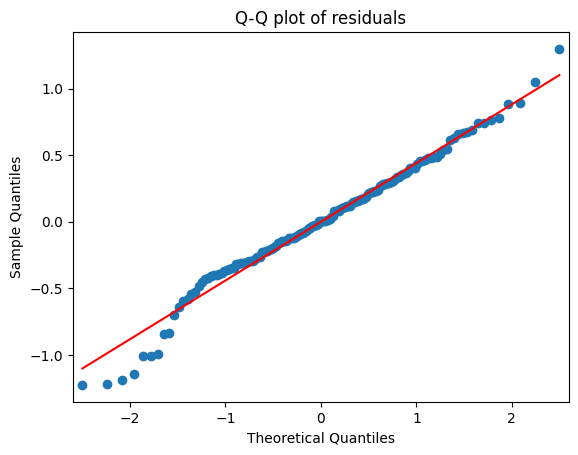

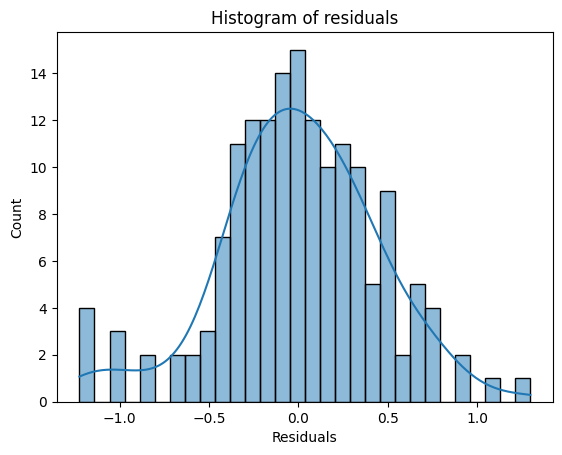

In [933]:
# Тест Шапиро-Уилка
shapiro_test = shapiro(results.resid)
print(f"Shapiro-Wilk test: {shapiro_test}")

# Q-Q plot
sm.qqplot(results.resid, line='s')
plt.title('Q-Q plot of residuals')
plt.show()

# Гистограмма остатков
sns.histplot(results.resid, kde=True, bins=30)
plt.xlabel('Residuals')
plt.title('Histogram of residuals')
plt.show()

# Челябинск 2008

In [934]:
df_Chelyabinsk_2008['lnWage'] = np.log(df_Chelyabinsk_2008['wage'])
df_Chelyabinsk_2008 = df_Chelyabinsk_2008.drop(columns = ['wage'], axis = 1)
df_Chelyabinsk_2008.head()

,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours,lnWage
2068,1,68.0,4624.00,0.0,0.0,0.0,0.0,0.0,1,0.0,12.0,10.087058
2069,0,36.5,1332.25,2.0,0.0,0.0,0.0,0.0,1,0.0,9.0,10.821028
2073,1,60.0,3600.00,0.0,1.0,1.0,1.0,0.0,1,0.0,8.0,10.310202
2075,0,60.5,3660.25,0.0,0.0,0.0,1.0,0.0,1,0.0,11.0,10.204841
2076,1,28.5,812.25,1.0,1.0,0.0,1.0,0.0,1,1.0,8.0,10.310202


In [935]:
#df_Chelyabinsk_2008['age'] = df_Chelyabinsk_2008['age'] - df_Chelyabinsk_2008['age'].mean()
#df_Chelyabinsk_2008['age^2'] = df_Chelyabinsk_2008['age'] ** 2 

X = df_Chelyabinsk_2008[['sex', 'age', 'age^2', 'children', 'married', 'is_supervisor', 'qualification', 'diplom', 'health', 'language', 'working hours']]
y = df_Chelyabinsk_2008['lnWage']
X = sm.add_constant(X)  
model = sm.OLS(y, X)   
results = model.fit()  
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                 lnWage   R-squared:                       0.343
Model:                            OLS   Adj. R-squared:                  0.243
Method:                 Least Squares   F-statistic:                     3.421
Date:                Mon, 22 Dec 2025   Prob (F-statistic):           0.000742
Time:                        11:31:59   Log-Likelihood:                -62.922
No. Observations:                  84   AIC:                             149.8
Df Residuals:                      72   BIC:                             179.0
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             7.0769      0.818      8.654

In [936]:
vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif

,Variable,VIF
0,const,183.815372
1,sex,1.142489
2,age,58.975023
3,age^2,57.105281
4,children,1.363758
5,married,1.281262
6,is_supervisor,1.325074
7,qualification,1.359448
8,diplom,1.333850
9,health,1.114236


In [937]:
# Тест Бройша-Пагана
bp_test = het_breuschpagan(results.resid, results.model.exog)
labels_bp = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print("Breusch-Pagan test:", dict(zip(labels_bp, bp_test)))

Breusch-Pagan test: {'LM Statistic': np.float64(12.993817751838098), 'LM-Test p-value': np.float64(0.293729670670458), 'F-Statistic': np.float64(1.1977892737470515), 'F-Test p-value': np.float64(0.3042794667279969)}


In [938]:
# Тест Уайта
white_test = het_white(results.resid, results.model.exog)
labels_white = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Statistic p-value']
print("White test:", dict(zip(labels_white, white_test)))

White test: {'Test Statistic': np.float64(57.52371822834315), 'Test Statistic p-value': np.float64(0.530093023331388), 'F-Statistic': np.float64(0.8837902090318935), 'F-Statistic p-value': np.float64(0.6590179371420756)}


In [939]:
# Goldfeld-Quandt
gq_test = het_goldfeldquandt(results.resid, results.model.exog)
labels_gq = ['F-Statistic', 'p-value', 'Alternative']
print("Goldfeld-Quandt test:", dict(zip(labels_gq, gq_test)))

Goldfeld-Quandt test: {'F-Statistic': np.float64(1.7215537811995145), 'p-value': np.float64(0.07125629870932644), 'Alternative': 'increasing'}


In [940]:
# Jarque-Bera
jb_test = jarque_bera(results.resid)
labels_jb = ['JB Statistic', 'p-value', 'Skew', 'Kurtosis']
print("Jarque-Bera test:", dict(zip(labels_jb, jb_test)))

Jarque-Bera test: {'JB Statistic': np.float64(1.405688444806012), 'p-value': np.float64(0.4951749114309294), 'Skew': np.float64(-0.2772917808578267), 'Kurtosis': np.float64(2.693304152262612)}


Shapiro-Wilk test: ShapiroResult(statistic=np.float64(0.9824988989823061), pvalue=np.float64(0.31169695476733694))


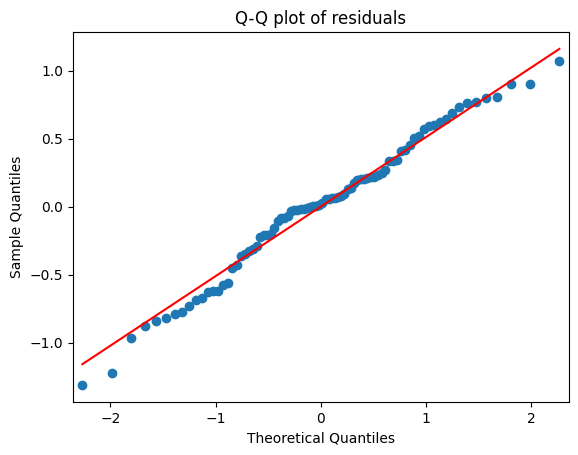

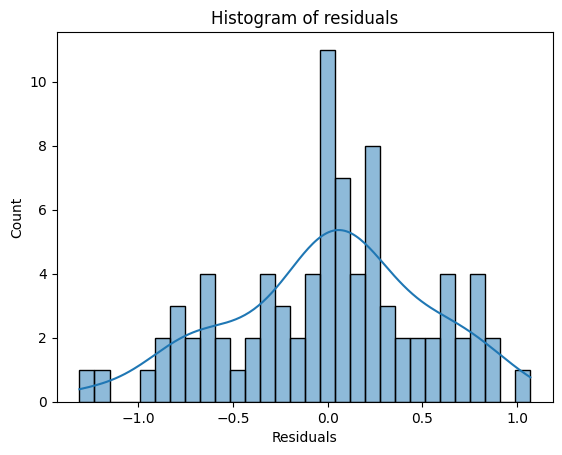

In [941]:
# Тест Шапиро-Уилка
shapiro_test = shapiro(results.resid)
print(f"Shapiro-Wilk test: {shapiro_test}")

# Q-Q plot
sm.qqplot(results.resid, line='s')
plt.title('Q-Q plot of residuals')
plt.show()

# Гистограмма остатков
sns.histplot(results.resid, kde=True, bins=30)
plt.xlabel('Residuals')
plt.title('Histogram of residuals')
plt.show()

# Липецк 2015

In [942]:
df_Lipetsk_2015['lnWage'] = np.log(df_Lipetsk_2015['wage'])
df_Lipetsk_2015 = df_Lipetsk_2015.drop(columns = ['wage'], axis = 1)
df_Lipetsk_2015.head()

,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours,lnWage
800,0,58.5,3422.25,0.0,0.0,0.0,1.0,0.0,1.0,0.0,8.0,9.546813
801,0,29.5,870.25,0.0,0.0,0.0,0.0,1.0,1.0,0.0,12.0,9.472705
802,0,38.0,1444.00,2.0,1.0,0.0,0.0,0.0,1.0,0.0,8.0,9.433484
804,0,52.0,2704.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,9.035987
805,1,29.0,841.00,1.0,1.0,0.0,1.0,1.0,1.0,0.0,8.0,9.852194


In [943]:
#df_Lipetsk_2015['age'] = df_Lipetsk_2015['age'] - df_Lipetsk_2015['age'].mean()
#df_Lipetsk_2015['age^2'] = df_Lipetsk_2015['age'] ** 2 

X = df_Lipetsk_2015[['sex', 'age', 'age^2', 'children', 'married', 'is_supervisor', 'qualification', 'diplom', 'health', 'language', 'working hours']]
y = df_Lipetsk_2015['lnWage']
X = sm.add_constant(X)  
model = sm.OLS(y, X)   
results = model.fit()  
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                 lnWage   R-squared:                       0.503
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     13.51
Date:                Mon, 22 Dec 2025   Prob (F-statistic):           1.37e-17
Time:                        11:32:31   Log-Likelihood:                -64.588
No. Observations:                 159   AIC:                             153.2
Df Residuals:                     147   BIC:                             190.0
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             8.2029      0.412     19.934

In [944]:
vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif

,Variable,VIF
0,const,188.672101
1,sex,1.244158
2,age,54.470216
3,age^2,54.587512
4,children,1.612072
5,married,1.441687
6,is_supervisor,1.071378
7,qualification,1.307572
8,diplom,1.418205
9,health,1.069948


In [945]:
# Тест Бройша-Пагана
bp_test = het_breuschpagan(results.resid, results.model.exog)
labels_bp = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print("Breusch-Pagan test:", dict(zip(labels_bp, bp_test)))

Breusch-Pagan test: {'LM Statistic': np.float64(9.40945200140202), 'LM-Test p-value': np.float64(0.5841534920279705), 'F-Statistic': np.float64(0.840591177786216), 'F-Test p-value': np.float64(0.599888731385903)}


In [946]:
# Тест Уайта
white_test = het_white(results.resid, results.model.exog)
labels_white = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Statistic p-value']
print("White test:", dict(zip(labels_white, white_test)))

White test: {'Test Statistic': np.float64(69.29221296905611), 'Test Statistic p-value': np.float64(0.36702216021295614), 'F-Statistic': np.float64(1.0767085951801254), 'F-Statistic p-value': np.float64(0.3683976034733728)}


In [947]:
# Goldfeld-Quandt
gq_test = het_goldfeldquandt(results.resid, results.model.exog)
labels_gq = ['F-Statistic', 'p-value', 'Alternative']
print("Goldfeld-Quandt test:", dict(zip(labels_gq, gq_test)))

Goldfeld-Quandt test: {'F-Statistic': np.float64(1.105011969282791), 'p-value': np.float64(0.3411812005513756), 'Alternative': 'increasing'}


In [948]:
# Jarque-Bera
jb_test = jarque_bera(results.resid)
labels_jb = ['JB Statistic', 'p-value', 'Skew', 'Kurtosis']
print("Jarque-Bera test:", dict(zip(labels_jb, jb_test)))

Jarque-Bera test: {'JB Statistic': np.float64(93.01334634481432), 'p-value': np.float64(6.344661689187224e-21), 'Skew': np.float64(-1.1034840403000123), 'Kurtosis': np.float64(6.028042648788608)}


Shapiro-Wilk test: ShapiroResult(statistic=np.float64(0.9409659115659713), pvalue=np.float64(3.467505379193022e-06))


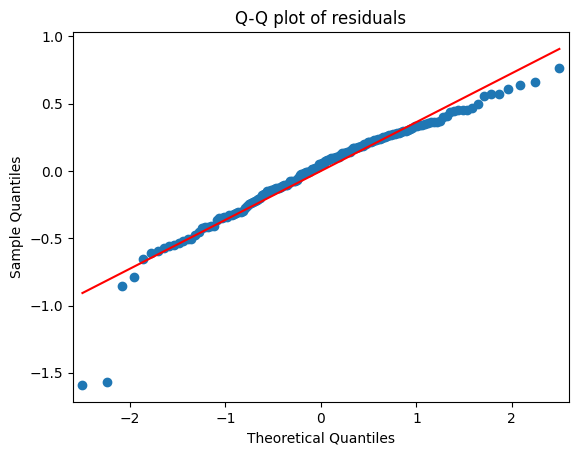

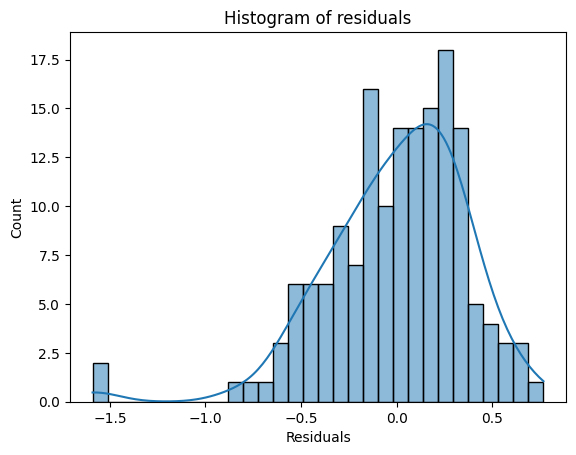

In [949]:
# Тест Шапиро-Уилка
shapiro_test = shapiro(results.resid)
print(f"Shapiro-Wilk test: {shapiro_test}")

# Q-Q plot
sm.qqplot(results.resid, line='s')
plt.title('Q-Q plot of residuals')
plt.show()

# Гистограмма остатков
sns.histplot(results.resid, kde=True, bins=30)
plt.xlabel('Residuals')
plt.title('Histogram of residuals')
plt.show()

# Челябинск 2015

In [950]:
df_Chelyabinsk_2015['lnWage'] = np.log(df_Chelyabinsk_2015['wage'])
df_Chelyabinsk_2015 = df_Chelyabinsk_2015.drop(columns = ['wage'], axis = 1)
df_Chelyabinsk_2015.head()

,sex,age,age^2,children,married,is_supervisor,qualification,diplom,health,language,working hours,lnWage
1321,1,44.0,1936.00,1.0,1.0,0.0,1.0,0.0,1,0.0,11.0,10.126631
1322,0,42.0,1764.00,1.0,0.0,1.0,1.0,1.0,1,0.0,8.0,10.714418
1324,1,35.5,1260.25,2.0,1.0,0.0,1.0,0.0,1,0.0,9.0,10.126631
1327,0,69.5,4830.25,0.0,0.0,0.0,1.0,1.0,1,0.0,5.0,9.648595
1328,0,62.0,3844.00,0.0,1.0,0.0,1.0,1.0,1,0.0,8.0,9.615805


In [951]:
#df_Chelyabinsk_2015['age'] = df_Chelyabinsk_2015['age'] - df_Chelyabinsk_2015['age'].mean()
#df_Chelyabinsk_2015['age^2'] = - df_Chelyabinsk_2015['age'] ** 2 

X = df_Chelyabinsk_2015[['sex', 'age', 'age^2', 'children', 'married', 'is_supervisor', 'qualification', 'diplom', 'health', 'language', 'working hours']]
y = df_Chelyabinsk_2015['lnWage']
X = sm.add_constant(X)  
model = sm.OLS(y, X)   
results = model.fit()  
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                 lnWage   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.232
Method:                 Least Squares   F-statistic:                     4.236
Date:                Mon, 22 Dec 2025   Prob (F-statistic):           3.25e-05
Time:                        11:32:55   Log-Likelihood:                -82.780
No. Observations:                 119   AIC:                             189.6
Df Residuals:                     107   BIC:                             222.9
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             7.9629      0.660     12.067

In [952]:
vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif

,Variable,VIF
0,const,197.960583
1,sex,1.162959
2,age,39.938579
3,age^2,40.005085
4,children,1.387442
5,married,1.262734
6,is_supervisor,1.105998
7,qualification,1.334378
8,diplom,1.565569
9,health,1.181639


In [953]:
# Тест Бройша-Пагана
bp_test = het_breuschpagan(results.resid, results.model.exog)
labels_bp = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print("Breusch-Pagan test:", dict(zip(labels_bp, bp_test)))

Breusch-Pagan test: {'LM Statistic': np.float64(2.9613258729611607), 'LM-Test p-value': np.float64(0.9912271634279682), 'F-Statistic': np.float64(0.24824158512088765), 'F-Test p-value': np.float64(0.9930226619841326)}


In [954]:
# Тест Уайта
white_test = het_white(results.resid, results.model.exog)
labels_white = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Statistic p-value']
print("White test:", dict(zip(labels_white, white_test)))

White test: {'Test Statistic': np.float64(34.68910163664533), 'Test Statistic p-value': np.float64(0.997337719336927), 'F-Statistic': np.float64(0.38446282837197093), 'F-Statistic p-value': np.float64(0.9998464269439943)}


In [955]:
# Goldfeld-Quandt
gq_test = het_goldfeldquandt(results.resid, results.model.exog)
labels_gq = ['F-Statistic', 'p-value', 'Alternative']
print("Goldfeld-Quandt test:", dict(zip(labels_gq, gq_test)))

Goldfeld-Quandt test: {'F-Statistic': np.float64(0.33431143880223874), 'p-value': np.float64(0.9998741432200431), 'Alternative': 'increasing'}


In [956]:
# Jarque-Bera
jb_test = jarque_bera(results.resid)
labels_jb = ['JB Statistic', 'p-value', 'Skew', 'Kurtosis']
print("Jarque-Bera test:", dict(zip(labels_jb, jb_test)))

Jarque-Bera test: {'JB Statistic': np.float64(232.81183184958638), 'p-value': np.float64(2.789671418925088e-51), 'Skew': np.float64(-1.6646701093943257), 'Kurtosis': np.float64(8.98908511102796)}


Shapiro-Wilk test: ShapiroResult(statistic=np.float64(0.8929321859321907), pvalue=np.float64(9.575424585850859e-08))


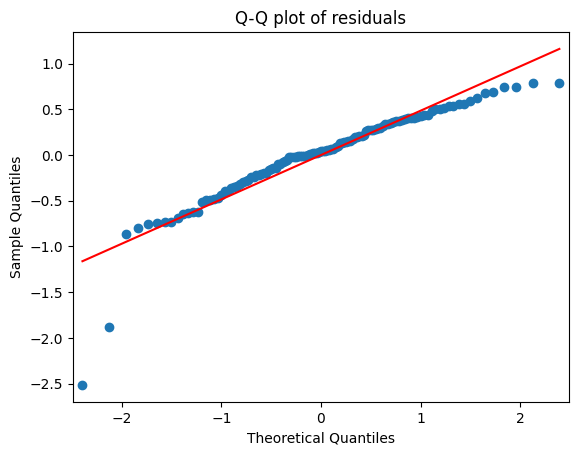

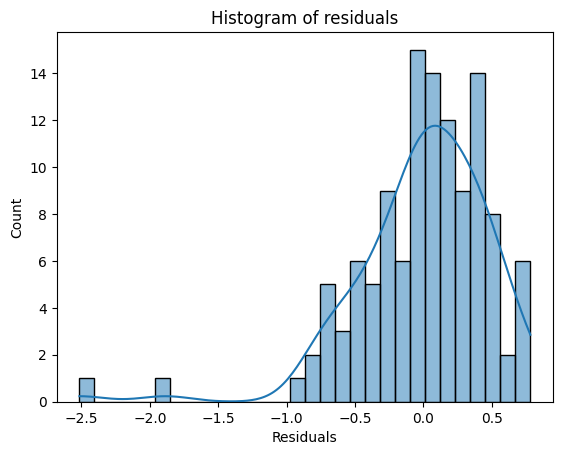

In [957]:
# Тест Шапиро-Уилка
shapiro_test = shapiro(results.resid)
print(f"Shapiro-Wilk test: {shapiro_test}")

# Q-Q plot
sm.qqplot(results.resid, line='s')
plt.title('Q-Q plot of residuals')
plt.show()

# Гистограмма остатков
sns.histplot(results.resid, kde=True, bins=30)
plt.xlabel('Residuals')
plt.title('Histogram of residuals')
plt.show()